In [1]:
import os
import numpy as np
import librosa
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
from sklearn.utils import shuffle

2025-06-19 09:16:41.505428: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750324601.686369      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750324601.742756      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [ ]:
# 🗂 Dataset path
non_music_path = ""
music_path = ""

In [3]:
non_music_files = [os.path.join(non_music_path, f) for f in os.listdir(non_music_path)]
music_files = [os.path.join(music_path, f) for f in os.listdir(music_path)]

In [4]:
non_music_labels = np.zeros(len(non_music_files))
music_labels = np.ones(len(music_files))

In [5]:
# Combine all file paths and labels
all_files = non_music_files + music_files
all_labels = np.concatenate([non_music_labels, music_labels])


In [6]:
#shuffle the dataset

all_files, all_labels = shuffle(all_files, all_labels, random_state=42)


In [7]:
# ⚙️ Audio Parameters
SAMPLE_RATE = 22050
DURATION = 5  # seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION
MFCC_FEATURES = 40
MAX_PAD_LEN = 130  # Adjust based on testing

In [17]:
#gpu setup
def setup_gpus():
    """Robust multi-GPU setup with proper error handling"""
    
    # Clear any previous distributed strategy
    tf.keras.backend.clear_session()
    
    # Configure GPU memory growth BEFORE creating strategy
    gpus = tf.config.list_physical_devices('GPU')
    print(f"Available GPUs: {len(gpus)}")
    for gpu in gpus:
        print(f"  - {gpu}")
    
    if len(gpus) == 0:
        print("No GPUs found, using CPU")
        return None, 1
    
    # CRITICAL: Set memory growth for ALL GPUs before strategy creation
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth configured for all GPUs")
    except RuntimeError as e:
        print(f"Memory growth error (may be already set): {e}")
    
    try:
        strategy = tf.distribute.MirroredStrategy(
            cross_device_ops=tf.distribute.HierarchicalCopyAllReduce()
        )
        strategy = tf.distribute.MirroredStrategy()  # for multi-GPU / multi-device training

        print(f"MirroredStrategy created with {strategy.num_replicas_in_sync} replicas")
        return strategy, strategy.num_replicas_in_sync
    except Exception as e:
        print(f"MirroredStrategy creation failed: {e}")
        print("Falling back to single GPU")
        return None, 1


In [18]:
strategy=setup_gpus()

Available GPUs: 2
  - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  - PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
Memory growth configured for all GPUs
MirroredStrategy created with 2 replicas


In [10]:
# 📥 Load data and extract MFCCs
def extract_features(file_path):
    try:
        signal, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
        mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=MFCC_FEATURES)

        if mfcc.shape[1] < MAX_PAD_LEN:
            pad_width = MAX_PAD_LEN - mfcc.shape[1]
            mfcc = np.pad(mfcc, pad_width=((0, 0), (0, pad_width)), mode='constant')
        else:
            mfcc = mfcc[:, :MAX_PAD_LEN]

        return mfcc.T  # shape: (time_steps, n_mfcc)
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def load_dataset(dataset_path):
    features = []
    labels = []
    for label in os.listdir(dataset_path):
        class_folder = os.path.join(dataset_path, label)
        if not os.path.isdir(class_folder):
            continue
        for file in os.listdir(class_folder):
            file_path = os.path.join(class_folder, file)
            mfcc = extract_features(file_path)
            if mfcc is not None:
                features.append(mfcc)
                labels.append(label)
    return np.array(features), np.array(labels)

In [11]:
from tqdm import tqdm  # Make sure to install with: pip install tqdm

# 🚀 Load data
features = []
valid_labels = []

# tqdm adds the progress bar
for file_path, label in tqdm(zip(all_files, all_labels), total=len(all_files), desc="🔄 Processing audio files"):
    mfcc = extract_features(file_path)
    if mfcc is not None:
        features.append(mfcc)
        valid_labels.append(label)

X = np.array(features)
y = np.array(valid_labels)


🔄 Processing audio files: 100%|██████████| 118788/118788 [1:23:47<00:00, 23.63it/s]


In [13]:
# 🔀 Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
def setup_gpu():
    physical_devices = tf.config.list_physical_devices('GPU')
    for device in physical_devices:
        try:
            tf.config.experimental.set_memory_growth(device, True)
        except RuntimeError as e:
            print(f"Error setting memory growth: {e}")

In [24]:
strategy = setup_gpu()

Failed to set GPU: Visible devices cannot be modified after being initialized


In [46]:

# 🧠 RNN Model (BiLSTM)
with strategy.scope():
    model = tf.keras.models.Sequential([
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=False), input_shape=(X_train.shape[1], X_train.shape[2])),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(2, activation='sigmoid')
    ])
    
    model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

    model.summary()
    
    # 🏋️ Train model
    history = model.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_test, y_test))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ bidirectional_3 (Bidirectional)      │ (None, 128)                 │          53,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 62,146 (242.76 KB)

 Trainable params: 62,146 (242.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9191 - loss: 0.1877 - val_accuracy: 0.9900 - val_loss: 0.0312
Epoch 2/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.9884 - loss: 0.0361 - val_accuracy: 0.9917 - val_loss: 0.0261
Epoch 3/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.9914 - loss: 0.0270 - val_accuracy: 0.9939 - val_loss: 0.0213
Epoch 4/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.9927 - loss: 0.0232 - val_accuracy: 0.9947 - val_loss: 0.0178
Epoch 5/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.9935 - loss: 0.0206 - val_accuracy: 0.9949 - val_loss: 0.0181
Epoch 6/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.9929 - loss: 0.0211 - val_accuracy: 0.9950 - val_loss: 0.0171
Epoch 7/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.9941 - loss: 0.0168 - val_accuracy: 0.9958 - val_loss: 0.0154
Epoch 8/10
1485/1485 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.9949 -

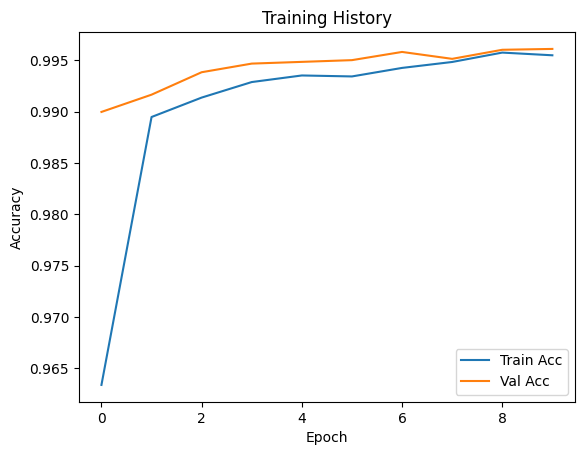

In [47]:

# 📊 Plot training history
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training History')
plt.show()


In [48]:

# 🧪 Evaluate
loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc:.2f}")


743/743 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9967 - loss: 0.0123
Test Accuracy: 1.00


In [49]:
def plot_accuracy_loss(history):
    plt.figure(figsize=(14, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', marker='o')
    plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


In [50]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()


In [51]:
from sklearn.metrics import classification_report

def print_classification_report(y_true, y_pred, class_names):
    print(classification_report(y_true, y_pred, target_names=class_names))


In [52]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

def plot_binary_roc(y_true, y_pred_probs):
    fpr, tpr, _ = roc_curve(y_true, y_pred_probs)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (Binary)')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()


In [53]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def plot_precision_recall(y_true, y_pred_probs, class_names):
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    plt.figure(figsize=(8, 6))
    for i in range(len(class_names)):
        precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_pred_probs[:, i])
        ap_score = average_precision_score(y_true_bin[:, i], y_pred_probs[:, i])
        plt.plot(recall, precision, label=f'{class_names[i]} (AP = {ap_score:.2f})')

    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.grid(True)
    plt.show()


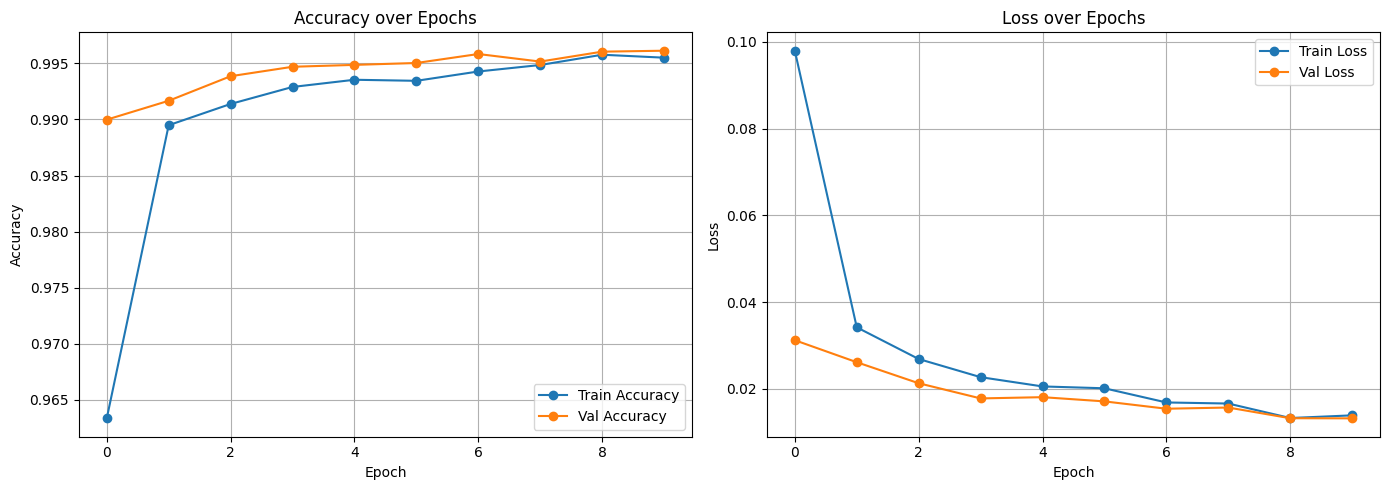

743/743 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step


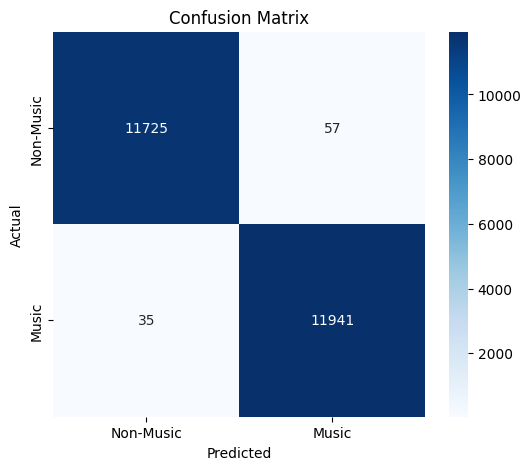

              precision    recall  f1-score   support

   Non-Music       1.00      1.00      1.00     11782
       Music       1.00      1.00      1.00     11976

    accuracy                           1.00     23758
   macro avg       1.00      1.00      1.00     23758
weighted avg       1.00      1.00      1.00     23758



In [58]:
# Assuming model was trained with:
# history = model.fit(...)

# 1. Plot learning curves
plot_accuracy_loss(history)

# 2. Predict
y_pred_probs = model.predict(X_test)
y_pred = y_pred_probs.argmax(axis=1)

# 3. Confusion matrix
plot_confusion_matrix(y_test, y_pred, class_names=["Non-Music", "Music"])

# 4. Report
print_classification_report(y_test, y_pred, class_names=["Non-Music", "Music"])





In [59]:
print("y_test shape:", y_test.shape)
print("y_pred_probs shape:", y_pred_probs.shape)


y_test shape: (23758,)
y_pred_probs shape: (23758, 2)


In [60]:
y_pred_probs = model.predict(X_test)


743/743 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step


In [61]:
y_pred_probs = model.predict(X_test, batch_size=64, verbose=1)
print(y_pred_probs.shape)


372/372 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
(23758, 2)


In [66]:
model.save("music_classifier_model2.h5")  # or any other name you prefer


In [44]:

model.save("music_classifier_model.keras")


In [71]:

# 🎵 Feature extraction function (same as in training)
def extract_features(file_path):
    try:
        signal, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
        mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=MFCC_FEATURES)


        if mfcc.shape[1] < MAX_PAD_LEN:
            pad_width = MAX_PAD_LEN - mfcc.shape[1]
            mfcc = np.pad(mfcc, pad_width=((0, 0), (0, pad_width)), mode='constant')
        else:
            mfcc = mfcc[:, :MAX_PAD_LEN]

        return mfcc.T  # shape: (time_steps, n_mfcc)
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# 🚀 Run prediction on test files
def test_model_on_folder(test_folder):
    
    class_names = ["NonMusic", "Music"]
    for label in os.listdir(test_folder):
        i=0
        j=0
        folder_path = os.path.join(test_folder, label)
        if not os.path.isdir(folder_path):
            continue

        print(f"\n📂 Testing on: {label} files")
        for file in os.listdir(folder_path):
            if not file.lower().endswith(".mp3"):
                continue

            file_path = os.path.join(folder_path, file)
            mfcc = extract_features(file_path)
            if mfcc is None:
                continue

            # Expand dimensions to match model input: (1, time_steps, n_mfcc)
            mfcc_input = np.expand_dims(mfcc, axis=0)
            prediction = model.predict(mfcc_input, verbose=0)
            predicted_class = np.argmax(prediction)
            confidence = prediction[0][predicted_class]

            print(f"🎧 {file} → Predicted: {class_names[predicted_class]} ({confidence:.2f})")
            if predicted_class == 1:
                i+=1
            else:
                j+=1
        print(i)
        print(j)

# 🔍 Run test
test_model_on_folder("")



📂 Testing on: Music files
🎧 music_70.mp3 → Predicted: Music (1.00)
🎧 music_30.mp3 → Predicted: Music (0.99)
🎧 music_83.mp3 → Predicted: Music (1.00)
🎧 music_67.mp3 → Predicted: Music (1.00)
🎧 music_78.mp3 → Predicted: Music (1.00)
🎧 music_34.mp3 → Predicted: Music (1.00)
🎧 music_40.mp3 → Predicted: Music (0.94)
🎧 music_98.mp3 → Predicted: Music (1.00)
🎧 music_99.mp3 → Predicted: Music (1.00)
🎧 music_75.mp3 → Predicted: Music (1.00)
🎧 music_55.mp3 → Predicted: Music (1.00)
🎧 music_58.mp3 → Predicted: Music (1.00)
🎧 music_92.mp3 → Predicted: Music (1.00)
🎧 music_0.mp3 → Predicted: Music (0.96)
🎧 music_62.mp3 → Predicted: Music (1.00)
🎧 music_49.mp3 → Predicted: Music (0.90)
🎧 music_52.mp3 → Predicted: Music (1.00)
🎧 music_27.mp3 → Predicted: Music (1.00)
🎧 music_50.mp3 → Predicted: Music (0.99)
🎧 music_7.mp3 → Predicted: Music (0.99)
🎧 music_33.mp3 → Predicted: Music (0.99)
🎧 music_87.mp3 → Predicted: Music (1.00)
🎧 music_94.mp3 → Predicted: Music (1.00)
🎧 music_1.mp3 → Predicted: Music